# asthma_GSE152004 NetCoS — disease signatures before the connectivity score

Asthmatic vs healthy-control nasal airway epithelium (GSE152004, 440 vs 254 samples). Section 0
describes the three disease-side CS inputs **before** any connectivity score, as in section 0 of
`data_exploration_ipf_CS_and_rankings.ipynb`: the DEG signature, the MITHrIL-propagated gene-level
signature and the MITHrIL pathway signature. CS distributions and drug rankings follow once the CS
runs exist.

Files (`connectivity_score/input/disease_signature_2025/asthma_GSE152004/`):
* DEG    : `asthma_GSE152004_signature_gene_id.csv` (`;`-separated, decimal comma; columns
  `gene_id, DE_log2_FC, std.error, t.value, p.value, adj.p.value`; rows = NCBI GeneID).
* MITHrIL: `asthma_GSE152004_mith3_signature.csv` (tab-separated; `gene_id, gene, Perturbation,
  p.value, adj.p.value`; nodes include genes, metabolites `chebi:` and miRNAs).
* pathways: `asthma_GSE152004_mith3_pathways.tsv` (tab-separated; `ID, Pathway Name,
  Corrected Accumulator, Adjusted pValue`).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)

DISEASE = 'asthma_GSE152004'
HERE = os.getcwd()
def _find_root(start):
    p = start
    for _ in range(6):
        if os.path.isdir(os.path.join(p, 'connectivity_score', 'input')):
            return p
        p = os.path.dirname(p)
    return None
NETCOS_ROOT = _find_root(HERE) or _find_root(os.path.dirname(HERE)) or \
    r'G:\My Drive\Professionale\Ricerca\Assegno di ricerca - Universita di Catania\netcos'

CS_IN = os.path.join(NETCOS_ROOT, 'connectivity_score', 'input', 'disease_signature_2025', DISEASE)
DEG_SIG_PATH  = os.path.join(CS_IN, f'{DISEASE}_signature_gene_id.csv')
MITH_SIG_PATH = os.path.join(CS_IN, f'{DISEASE}_mith3_signature.csv')
PW_SIG_PATH   = os.path.join(CS_IN, f'{DISEASE}_mith3_pathways.tsv')
IMG_DIR = os.path.join(NETCOS_ROOT, 'imgs', 'case_studies', DISEASE)
os.makedirs(IMG_DIR, exist_ok=True)

deg = pd.read_csv(DEG_SIG_PATH, sep=';', decimal=',', dtype={'gene_id': str})
mith = pd.read_csv(MITH_SIG_PATH, sep='\t', dtype={'gene_id': str})
deg['gene_id']  = deg['gene_id'].str.strip()
mith['gene_id'] = mith['gene_id'].str.strip()
print('DEG signature    :', deg.shape, '| cols:', list(deg.columns))
print('MITHrIL signature:', mith.shape, '| cols:', list(mith.columns))
deg.head(3)

DEG signature    : (15347, 6) | cols: ['gene_id', 'DE_log2_FC', 'std.error', 't.value', 'p.value', 'adj.p.value']
MITHrIL signature: (15825, 5) | cols: ['gene_id', 'gene', 'Perturbation', 'p.value', 'adj.p.value']


,gene_id,DE_log2_FC,std.error,t.value,p.value,adj.p.value
0,100,-0.121496,0.060202,-2.018132,0.043961,0.108539
1,10000,0.040960,0.028871,1.418702,0.156434,0.277037
2,100008588,0.181187,0.047164,3.841645,0.000133,0.001745


## 0. DEG vs MITHrIL disease signatures (before the connectivity score)

### 0.1 What is in the MITHrIL signature that is not in DEG?
Node classes by identifier: numeric Entrez id = gene, `chebi:` or `cpd:` (KEGG compound) =
metabolite, `gl:` = glycan, `dr:` = KEGG drug, anything else = miRNA (human `hsa-`, viral and
other-species miRNAs).

In [2]:
gid = mith['gene_id']
mith['node_class'] = np.select(
    [gid.str.fullmatch(r'\d+'), gid.str.startswith(('chebi', 'cpd:')), gid.str.startswith('gl:'), gid.str.startswith('dr:')],
    ['gene', 'metabolite', 'glycan', 'drug'], default='miRNA')
is_gene = mith['node_class'] == 'gene'
comp = mith['node_class'].value_counts()
comp['TOTAL'] = len(mith)
print(comp)

deg_ids  = set(deg['gene_id'])
mith_gene_ids = set(mith.loc[is_gene, 'gene_id'])
common = deg_ids & mith_gene_ids
print(f'\nDEG genes: {len(deg_ids)}   MITHrIL genes: {len(mith_gene_ids)}   common: {len(common)}')
print(f'in DEG only  : {len(deg_ids - mith_gene_ids)}')
print(f'in MITH only : {len(mith_gene_ids - deg_ids)}')

node_class
gene          11457
metabolite     2886
miRNA          1250
glycan          208
drug             24
TOTAL         15825
Name: count, dtype: int64

DEG genes: 15347   MITHrIL genes: 11457   common: 8296
in DEG only  : 7051
in MITH only : 3161


### 0.2 Do the per-gene values agree? (DEG log2FC vs MITHrIL perturbation)
Merge on `gene_id` (common genes) and correlate raw fold-change against propagated perturbation.

In [3]:
m = pd.merge(deg[['gene_id', 'DE_log2_FC', 'adj.p.value']].rename(columns={'adj.p.value': 'deg_adjp'}),
             mith.loc[is_gene, ['gene_id', 'gene', 'Perturbation', 'adj.p.value']].rename(columns={'adj.p.value': 'mith_adjp'}),
             on='gene_id', how='inner')
m = m.replace([np.inf, -np.inf], np.nan).dropna(subset=['DE_log2_FC', 'Perturbation'])
print('common genes with both values:', len(m))
pear = stats.pearsonr(m['DE_log2_FC'], m['Perturbation'])
spear = stats.spearmanr(m['DE_log2_FC'], m['Perturbation'])
sign_agree = (np.sign(m['DE_log2_FC']) == np.sign(m['Perturbation'])).mean()
print(f'Pearson  r = {pear.statistic:+.4f}  (p={pear.pvalue:.2e})')
print(f'Spearman r = {spear.statistic:+.4f}  (p={spear.pvalue:.2e})')
print(f'sign agreement = {sign_agree:.3f}  (0.5 = chance)')

common genes with both values: 8296
Pearson  r = +0.8888  (p=0.00e+00)
Spearman r = +0.9077  (p=0.00e+00)
sign agreement = 0.921  (0.5 = chance)


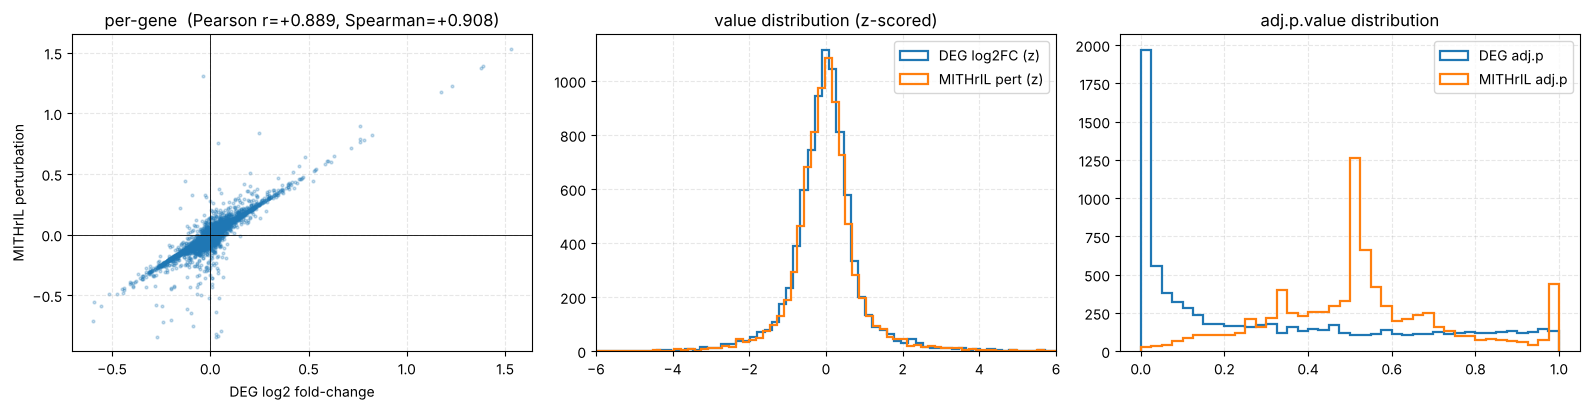

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].scatter(m['DE_log2_FC'], m['Perturbation'], s=4, alpha=0.25)
ax[0].axhline(0, color='k', lw=.6); ax[0].axvline(0, color='k', lw=.6)
ax[0].set_xlabel('DEG log2 fold-change'); ax[0].set_ylabel('MITHrIL perturbation')
ax[0].set_title(f'per-gene  (Pearson r={pear.statistic:+.3f}, Spearman={spear.statistic:+.3f})')
ax[0].grid(ls='--', alpha=.3)
ax[1].hist((m['DE_log2_FC']-m['DE_log2_FC'].mean())/m['DE_log2_FC'].std(), bins=120,
           histtype='step', lw=1.6, label='DEG log2FC (z)')
ax[1].hist((m['Perturbation']-m['Perturbation'].mean())/m['Perturbation'].std(), bins=120,
           histtype='step', lw=1.6, label='MITHrIL pert (z)')
ax[1].set_title('value distribution (z-scored)'); ax[1].legend(); ax[1].grid(ls='--', alpha=.3)
ax[1].set_xlim(-6, 6)
ax[2].hist(m['deg_adjp'], bins=40, histtype='step', lw=1.6, label='DEG adj.p')
ax[2].hist(m['mith_adjp'], bins=40, histtype='step', lw=1.6, label='MITHrIL adj.p')
ax[2].set_title('adj.p.value distribution'); ax[2].legend(); ax[2].grid(ls='--', alpha=.3)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_deg_vs_mith_signature.png'), dpi=120)
plt.show()

### 0.3 Significance agreement
How often is a gene significant (adj.p ≤ 0.05) in DEG vs after MITHrIL propagation?

In [5]:
deg_sig  = m['deg_adjp']  <= 0.05
mith_sig = m['mith_adjp'] <= 0.05
ct = pd.crosstab(deg_sig.rename('DEG_sig'), mith_sig.rename('MITH_sig'))
print(ct)
print(f"\nDEG-significant genes  : {deg_sig.mean():.1%}")
print(f"MITH-significant genes : {mith_sig.mean():.1%}")
print(f"significant in BOTH    : {(deg_sig & mith_sig).mean():.1%}")

MITH_sig  False  True 
DEG_sig               
False      5753     16
True       2482     45

DEG-significant genes  : 30.5%
MITH-significant genes : 0.7%
significant in BOTH    : 0.5%


### 0.4 Known-answer genes in both signatures
Airway type-2 epithelial genes, expected higher in asthma: is the sign kept after propagation?
CLCA1 is not in the DEG signature (removed by the expression filter); POSTN and CST1 are not
nodes of the MITHrIL network.

In [6]:
KNOWN_UP = {'POSTN': '10631', 'CLCA1': '1179', 'SERPINB2': '5055', 'CST1': '1469', 'CCL26': '10344'}
rows = []
for sym, gid in KNOWN_UP.items():
    d = deg[deg.gene_id == gid]; t = mith[mith.gene_id == gid]
    rows.append({'gene': sym, 'gene_id': gid,
                 'DEG log2FC': d['DE_log2_FC'].iloc[0] if len(d) else np.nan,
                 'DEG adj.p': d['adj.p.value'].iloc[0] if len(d) else np.nan,
                 'MITHrIL perturbation': t['Perturbation'].iloc[0] if len(t) else np.nan,
                 'MITHrIL adj.p': t['adj.p.value'].iloc[0] if len(t) else np.nan,
                 'MITHrIL rank (of genes, 1 = most positive)': int((mith.loc[is_gene, 'Perturbation'] > t['Perturbation'].iloc[0]).sum()) + 1 if len(t) else np.nan})
pd.DataFrame(rows).set_index('gene')

,gene_id,DEG log2FC,DEG adj.p,MITHrIL perturbation,MITHrIL adj.p,"MITHrIL rank (of genes, 1 = most positive)"
gene,,,,,,
POSTN,10631,0.973416,0.000078,NaN,NaN,NaN
CLCA1,1179,NaN,NaN,0.019005,0.000279,2925.0
SERPINB2,5055,0.483030,0.001656,0.636193,0.075356,16.0
CST1,1469,2.072907,0.000076,NaN,NaN,NaN
CCL26,10344,0.781293,0.000859,0.781526,0.034918,11.0


### 0.5 The pathway-level (`mith_pw`) signature

`mith_pw` scores drugs against a **pathway** signature: MITHrIL aggregates its node perturbations
into a per-pathway Corrected Accumulator (Reactome + KEGG). It cannot be compared gene by gene to
DEG/`mith`, so it is described on its own terms.

pathways: 2159 | unique IDs: 2159 | duplicated Pathway Names: 12
by DB: {'Reactome': 1926, 'KEGG': 233}
accumulator: min=-1.2  max=490.7  median=28.7  frac_negative=0.042
significant (adj_p<=0.05): 0.138  (299/2159)


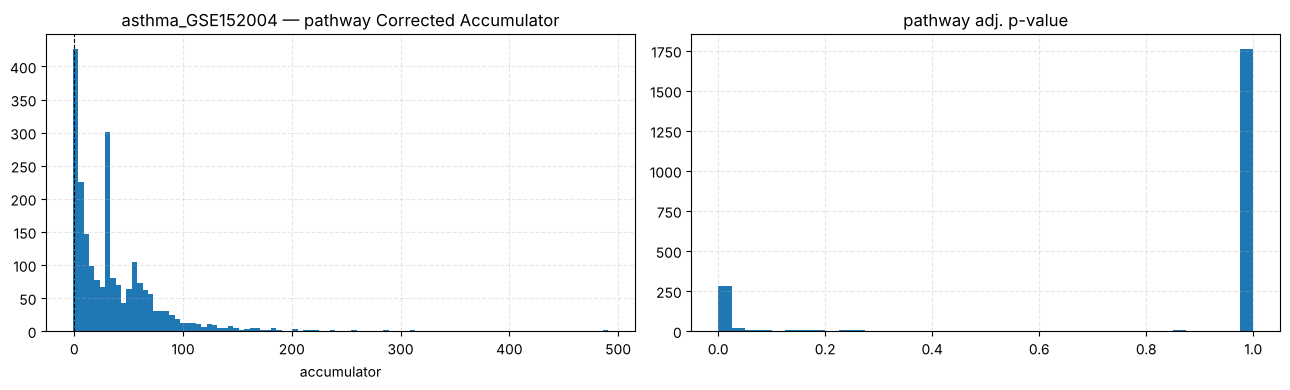

=== most POSITIVE (induced) pathways ===


,ID,Pathway Name,accumulator,adj_p,db
153,R-HSA-1430728,Metabolism,490.737507,1.0,Reactome
231,R-HSA-162582,Signaling Pathways,309.445990,1.0,Reactome
791,R-HSA-392499,Metabolism of proteins,285.017753,1.0,Reactome
748,R-HSA-382551,Transport of small molecules,256.464921,1.0,Reactome
2009,path:hsa01100,Metabolic pathways,254.710818,1.0,KEGG
1024,R-HSA-556833,Metabolism of lipids,239.715907,1.0,Reactome
212,R-HSA-15869,Nucleotide metabolism,220.574159,1.0,Reactome
295,R-HSA-168256,Immune System,218.152453,1.0,Reactome
1171,R-HSA-597592,Post-translational protein modification,215.172589,1.0,Reactome
1312,R-HSA-71291,Amino acid and derivative metabolism,211.981593,1.0,Reactome


=== most NEGATIVE (suppressed) pathways ===


,ID,Pathway Name,accumulator,adj_p,db
330,R-HSA-174577,Activation of C3 and C5,-1.217926,0.067435,Reactome
1819,R-HSA-9754189,Primitive streak formation,-0.948901,0.234557,Reactome
2086,path:hsa04612,Antigen processing and presentation,-0.874874,0.270509,KEGG
1545,R-HSA-8952158,RUNX3 regulates BCL2L11 (BIM) transcription,-0.633105,0.361646,Reactome
1072,R-HSA-5635851,GLI proteins bind promoters of Hh responsive g...,-0.579762,0.211375,Reactome
1749,R-HSA-9617828,FOXO-mediated transcription of cell cycle genes,-0.578518,0.860961,Reactome
1526,R-HSA-8941855,RUNX3 regulates CDKN1A transcription,-0.517372,0.933452,Reactome
1859,R-HSA-9796292,Formation of axial mesoderm,-0.491622,0.689967,Reactome
1874,R-HSA-9823730,Formation of definitive endoderm,-0.485695,1.000000,Reactome
1217,R-HSA-6804116,TP53 Regulates Transcription of Genes Involved...,-0.450992,1.000000,Reactome


In [7]:
pw = pd.read_csv(PW_SIG_PATH, sep='\t')
pw.columns = [c.strip() for c in pw.columns]
pw = pw.rename(columns={'Corrected Accumulator': 'accumulator', 'Adjusted pValue': 'adj_p'})
pw['ID'] = pw['ID'].astype(str).str.strip()
pw['db'] = np.where(pw['ID'].str.startswith('path:'), 'KEGG', 'Reactome')   # ID is the unique key

print('pathways:', len(pw), '| unique IDs:', pw.ID.nunique(),
      '| duplicated Pathway Names:', int(pw['Pathway Name'].duplicated().sum()))
print('by DB:', pw['db'].value_counts().to_dict())
print(f"accumulator: min={pw.accumulator.min():.1f}  max={pw.accumulator.max():.1f}  "
      f"median={pw.accumulator.median():.1f}  frac_negative={(pw.accumulator<0).mean():.3f}")
print(f"significant (adj_p<=0.05): {(pw.adj_p<=0.05).mean():.3f}  ({int((pw.adj_p<=0.05).sum())}/{len(pw)})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(pw.accumulator, bins=100); ax[0].axvline(0, color='k', lw=.8, ls='--')
ax[0].set_title(f'{DISEASE} — pathway Corrected Accumulator'); ax[0].set_xlabel('accumulator'); ax[0].grid(ls='--', alpha=.3)
ax[1].hist(pw.adj_p, bins=40); ax[1].set_title('pathway adj. p-value'); ax[1].grid(ls='--', alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_pathway_signature.png'), dpi=120); plt.show()

cols = ['ID', 'Pathway Name', 'accumulator', 'adj_p', 'db']
print('=== most POSITIVE (induced) pathways ==='); display(pw.sort_values('accumulator', ascending=False).head(15)[cols])
print('=== most NEGATIVE (suppressed) pathways ==='); display(pw.sort_values('accumulator').head(15)[cols])

### 0.6 Notes

- **Node sets.** DEG = 15,347 genes. MITHrIL = 15,825 network nodes (the same node set as the
  IPF and ALS runs): 11,457 genes, 2,886 metabolites, 208 glycans, 24 KEGG drugs, 1,250 miRNAs. 8,296 genes are in both; 7,051 DEG genes
  are not network nodes, and 3,161 MITHrIL gene nodes were not measured.
- **Per-gene values.** On the 8,296 shared genes, DEG log2FC and MITHrIL perturbation have
  Pearson r = 0.89, Spearman ρ = 0.91, sign agreement 0.92 (IPF: 0.71 / 0.84 / 0.87).
- **Significance.** 30.5% of the shared genes have DEG adj.p ≤ 0.05; 0.7% have MITHrIL
  adj.p ≤ 0.05, and 0.5% both.
- **Known-answer genes.** SERPINB2 and CCL26 keep a positive perturbation after propagation and
  rank 16th and 11th of the gene nodes by perturbation. CLCA1, absent from the DEG input, receives
  a small positive perturbation from its neighbours. POSTN and CST1, the two genes with the
  largest DEG fold-changes among them, are not network nodes, so they enter only the DEG runs.
- **Pathway signature.** 2,159 pathways (1,926 Reactome, 233 KEGG); 95.8% have a positive
  Corrected Accumulator (IPF ~78%), median 28.7, range −1.2 to 490.7; 299 (13.8%) have
  adj_p ≤ 0.05. The largest accumulators belong to the broadest pathways (Metabolism, Signaling
  Pathways, Metabolism of proteins, Immune System), all with adj_p = 1; the negative values are
  close to zero.